# How does an asthma drug change airway cells?

In **asthma**, the airways are inflamed: they swell, produce mucus and the muscles around them contract, so it's hard to breathe. Many asthma patients take **glucocorticoids**, drugs related to the stress hormone cortisol. One of them is **dexamethasone**. It calms the inflammation, but how?

Researchers (Himes et al. 2014) took **airway smooth muscle cells** from **4 donors** (people). They treated cells of each donor with dexamethasone for 18 hours and left other cells of the same donor untreated: **8 samples**.

### Your research question

> Which genes does dexamethasone switch **on** or **off** in airway muscle cells? Do these genes explain why it calms inflammation?

The data set is called `"airway"`. The genes are human genes.

In [1]:
setLanguage("en")   # language of the messages and plots below

Language: English



In [2]:
data <- loadDataset("airway")
data$samples

Loaded data set 'airway': 35619 genes, 8 samples.



,sample,donor,treatment
,<chr>,<fct>,<fct>
SRR1039512,SRR1039512,N052611,untreated
SRR1039520,SRR1039520,N061011,untreated
SRR1039516,SRR1039516,N080611,untreated
SRR1039508,SRR1039508,N61311,untreated
SRR1039513,SRR1039513,N052611,dex
SRR1039521,SRR1039521,N061011,dex
SRR1039517,SRR1039517,N080611,dex
SRR1039509,SRR1039509,N61311,dex


### Your steps

Work through the same steps as in the tutorial. You can copy code from `01_tutorial_milk.ipynb` and change it: the **column names** and **group names** are different here. Below each step there is a cell for your code, and a hint you can open if you get stuck.

| Step | Functions from the tutorial |
|---|---|
| 1 Look at the data | `DGEList`, `plotLibrarySizes` |
| 2 Define the groups | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Prepare | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design and contrast | `model.matrix`, `makeContrasts` |
| 5 Test | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Interpret | `plotVolcano`, `showTop`, `plotGene` |

If a cell gives an error, read the message, check the spelling of the names, and make sure you ran the cells above.

## 1 Look at the data

Make a `DGEList` and look at the library sizes. How many genes and samples are there?

[1] 35619     8

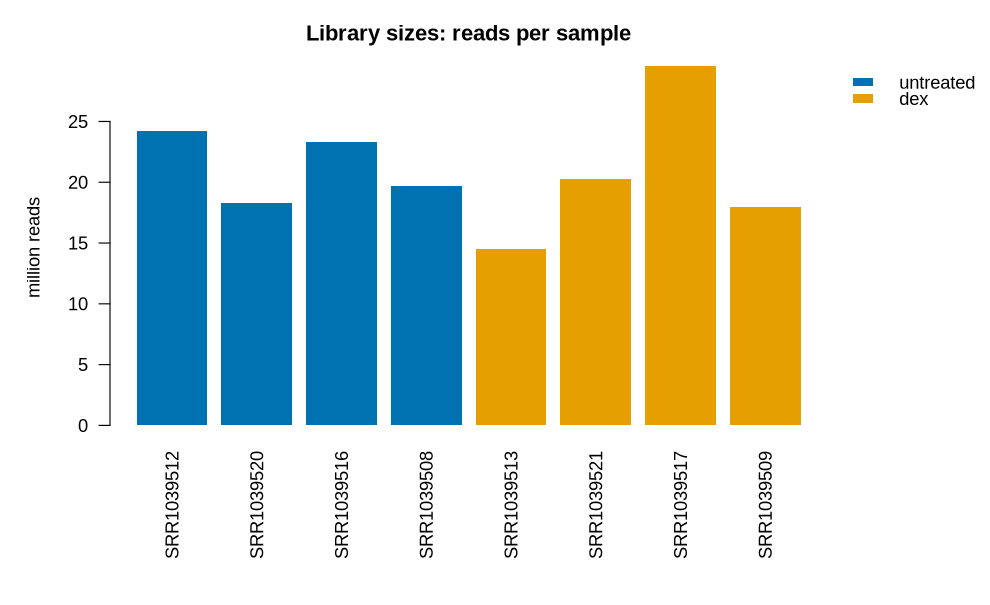

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "treatment")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

Exactly as in the tutorial, with `data` from this notebook. Colour by `"treatment"`.

</details>

## 2 Define the groups

Which column of the sample table contains the groups you want to compare? Store it as `dge$samples$group` and count the samples per group. Then check a known glucocorticoid gene: **FKBP5**.


untreated       dex 
        4         4 

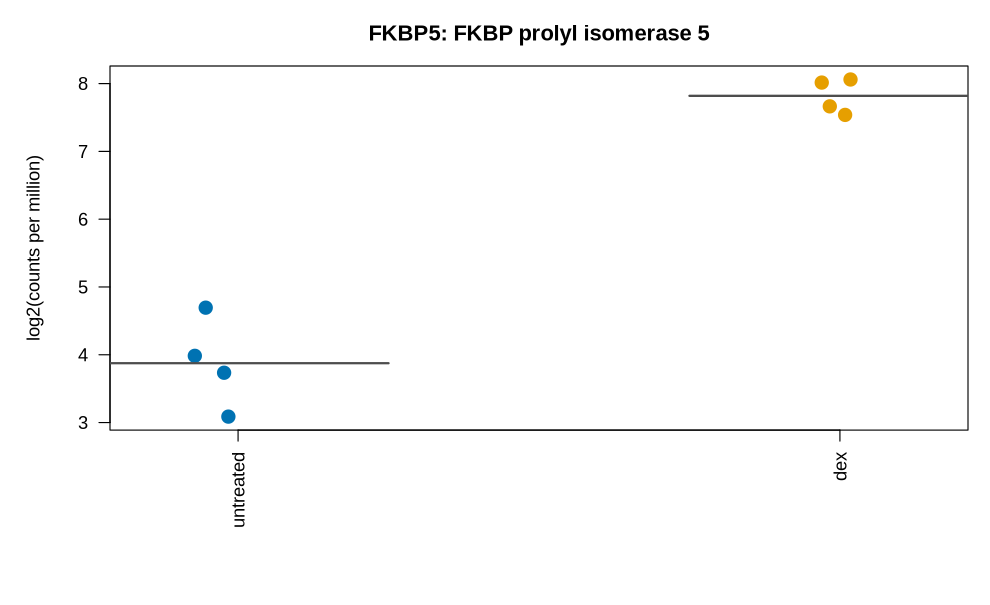

In [4]:
dge$samples$group <- dge$samples$treatment
table(dge$samples$group)
plotGene(dge, "FKBP5", group_by = "treatment")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

The groups are `untreated` and `dex`, in the column `treatment`: `dge$samples$group <- dge$samples$treatment`. The groups here are already ready, you don't need `paste`.

</details>

## 3 Prepare

Filter, normalise and draw the sample map. Colour it by treatment, then by donor.

[1] 13842     8

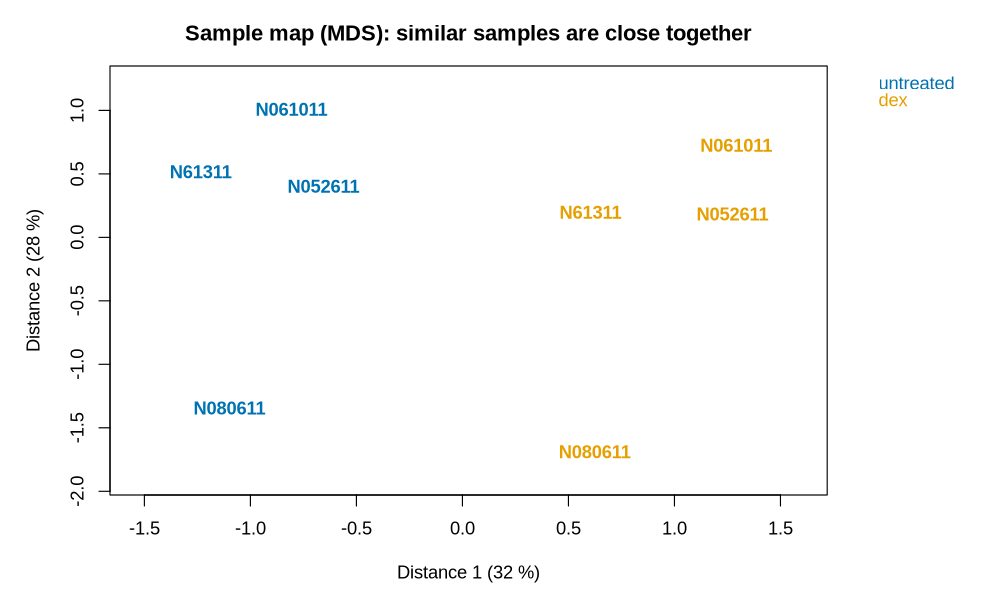

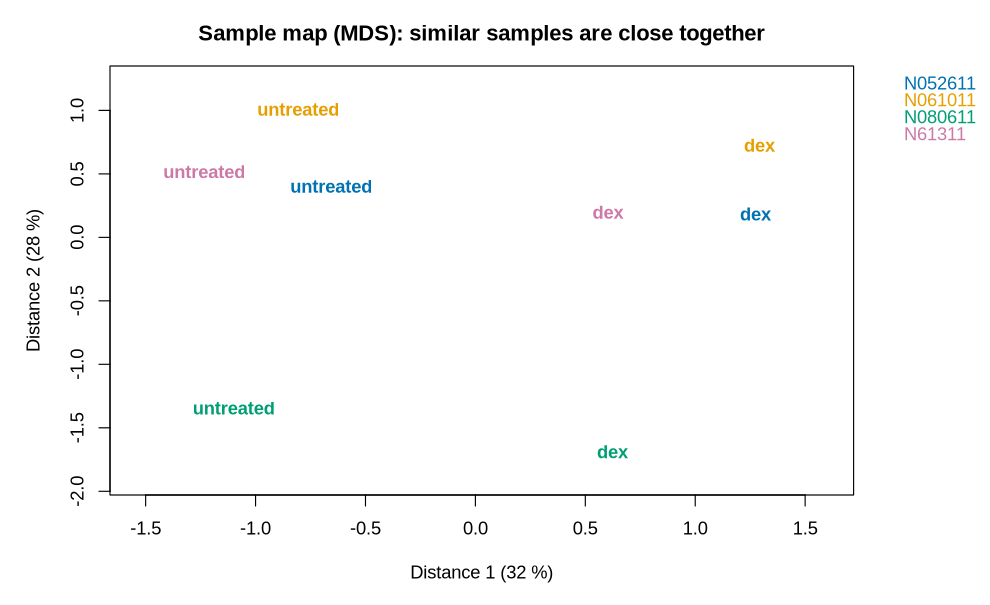

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "treatment", label_by = "donor")
plotSamples(dge, colour_by = "donor", label_by = "treatment")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

`filterByExpr`, then `dge[keep, , keep.lib.sizes = FALSE]`, then `normLibSizes`, as in part 3 of the tutorial. For the map: `plotSamples(dge, colour_by = "donor", label_by = "treatment")`.

</details>

**Question: What separates the samples along distance 1? And along distance 2?**

✅ **Answer:** About 13,800 genes remain. Distance 1 (32 %) separates **untreated from dexamethasone**. Distance 2 (28 %) separates the **donors**: the cells of one person resemble each other, treated or not. So the donor has almost as large an effect as the drug!

## 4 Design and contrast

Here is something new. Each donor gave **both** untreated and treated cells: a **paired** experiment. Since donors differ a lot (step 3), we compare each donor's treated cells with **their own** untreated cells. You tell limma by adding the donor to the design:

```r
design <- model.matrix(~0 + treatment + donor, data = dge$samples)
```

Look at the column names of this design, then write the contrast `dex_vs_untreated`.

In [6]:
design <- model.matrix(~0 + treatment + donor, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design)
contrasts

[1] "treatmentuntreated" "treatmentdex"       "donorN061011"       "donorN080611"       "donorN61311"

,dex_vs_untreated
treatmentuntreated,-1
treatmentdex,1
donorN061011,0
donorN080611,0
donorN61311,0


<details><summary>💡 <b>Hint</b> (click to open)</summary>

The columns are called `treatmentuntreated`, `treatmentdex`, and one column per donor (except the first). The donor columns only soak up the donor differences; the contrast uses the two treatment columns: `makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design)`.

</details>

## 5 Test

Run `voom`, `lmFit`, `contrasts.fit` and `eBayes`, and count the significant genes.

       dex_vs_untreated
Down               2264
NotSig             9280
Up                 2298

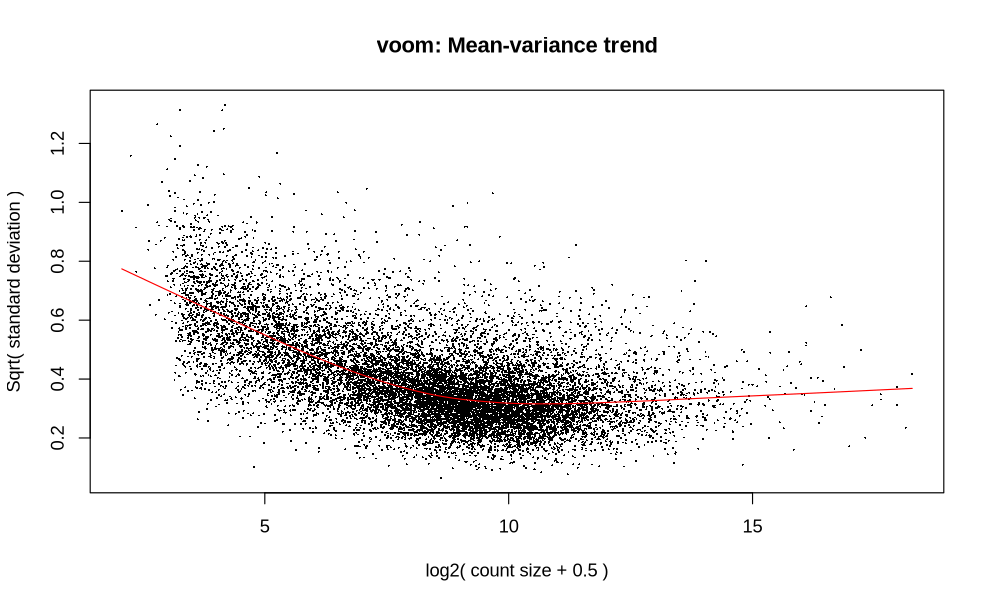

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Hint</b> (click to open)</summary>

Copy the two cells from part 5 of the tutorial; they work unchanged.

</details>

**Question: How many genes go up, how many down?**

✅ **Answer:** About **2,300 up** and **2,260 down** (adjusted p < 0.05).

## 6 Interpret

Draw the volcano plot and list the top genes going up and down. Look up some of them. Which ones have to do with **inflammation** or the **immune system**?

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
CACNB2,calcium voltage-gated channel auxiliary sub…,3.27,9.6× higher,3.7,1.1e-06
ALOX15B,arachidonate 15-lipoxygenase type B,8.05,265.7× higher,-1.4,2.6e-06
DUSP1,dual specificity phosphatase 1,2.93,7.6× higher,6.7,2.6e-06
PDPN,podoplanin,1.87,3.7× higher,5.3,2.6e-06
STEAP2,STEAP2 metalloreductase,1.96,3.9× higher,6.9,2.6e-06
SPARCL1,SPARC like 1,4.55,23.4× higher,4.2,2.6e-06
MAOA,monoamine oxidase A,3.32,10.0× higher,6.0,2.6e-06
FGD4,"FYVE, RhoGEF and PH domain containing 4",2.21,4.6× higher,5.5,2.7e-06
NEXN,nexilin F-actin binding protein,2.02,4.1× higher,7.7,2.7e-06


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
PRSS35,serine protease 35,-2.76,6.8× lower,3.3,2.6e-06
WNT2,Wnt family member 2,-3.09,8.5× lower,2.8,2.7e-06
DNM1,dynamin 1,-1.78,3.4× lower,5.2,3.0e-06
ADAM12,ADAM metallopeptidase domain 12,-1.83,3.6× lower,5.7,3.4e-06
CCKAR,cholecystokinin A receptor,-2.20,4.6× lower,5.0,4.1e-06
VCAM1,vascular cell adhesion molecule 1,-3.62,12.3× lower,3.6,4.2e-06
GXYLT2,glucoside xylosyltransferase 2,-1.59,3.0× lower,5.0,4.3e-06
CXCL12,C-X-C motif chemokine ligand 12,-1.92,3.8× lower,9.9,6.6e-06
KCTD12,potassium channel tetramerization domain co…,-2.54,5.8× lower,6.5,7.1e-06


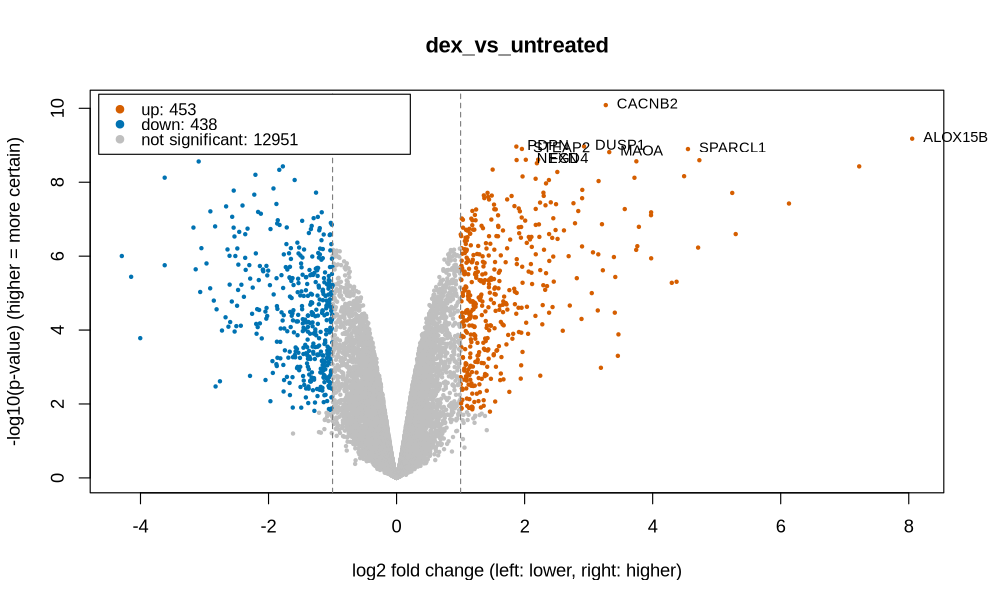

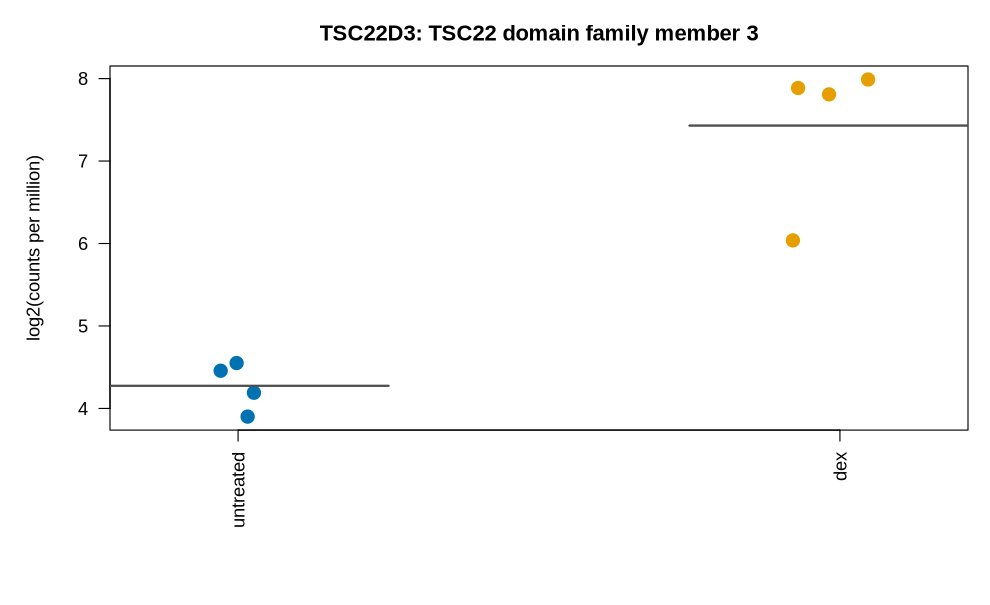

In [8]:
plotVolcano(fit, "dex_vs_untreated")
showTop(fit, "dex_vs_untreated", n = 20, direction = "up")
showTop(fit, "dex_vs_untreated", n = 20, direction = "down")
plotGene(dge, "TSC22D3", group_by = "treatment")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

Look up genes on [GeneCards](https://www.genecards.org). Some well-known glucocorticoid genes to check with `plotGene`: **DUSP1**, **TSC22D3** (also called GILZ, "glucocorticoid-induced leucine zipper"), **KLF15**, **PER1**, **ZBTB16**. Among the genes going down, look for **VCAM1** and **CXCL12**.

</details>

## Your conclusion

Answer the research question in a few sentences: what did you compare, what did you find, and what does it mean? Be ready to show your volcano plot and your answer to the class.

✅ **Answer:** We compared airway smooth muscle cells of 4 donors with and without dexamethasone, using a paired design (donor in the model). About 2,300 genes went up and 2,260 down. Up: classic glucocorticoid response genes such as *DUSP1*, *TSC22D3* (GILZ), *KLF15*, *PER1*, *FKBP5* and *ZBTB16*. DUSP1 and GILZ are **brakes of inflammation**: DUSP1 switches off inflammatory signalling, GILZ blocks the inflammatory master switch NF-κB. Down: *VCAM1*, which lets immune cells stick to tissue, and the chemokine *CXCL12*, which attracts immune cells. So dexamethasone turns on anti-inflammatory genes and turns off genes that call immune cells in: that explains how it calms the airways.

## Bonus: does the paired design matter?

Repeat steps 4 and 5 **without** the donor: `model.matrix(~0 + treatment, data = dge$samples)`. Compare the number of significant genes. Why is it different?

In [9]:
design0 <- model.matrix(~0 + treatment, data = dge$samples)
contrasts0 <- makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design0)
fit0 <- eBayes(contrasts.fit(lmFit(voom(dge, design0), design0), contrasts0))
summary(decideTests(fit0))

       dex_vs_untreated
Down                861
NotSig            11995
Up                  986

✅ **Answer:** Without the donor only about **1,850** genes are significant instead of about **4,560**. Without the donor in the model, the differences between donors count as "noise", so the noise looks bigger and fewer changes are convincing. With the paired design, limma compares each donor with themself, and the donor differences are removed.

<small>Software: limma (Ritchie et al. 2015) with voom (Law et al. 2014) and edgeR (Chen et al. 2025) in R. Full sources for all data sets at the end of `01_tutorial_milk.ipynb`.</small>